# Chapter 15 | Worked solutions

*Delta Rules and Hybrid Stacks*

These solutions cover all ten exercises, from a hand calculation to a controlled comparison. A delta update corrects a prediction at a key; overlapping queries can feel that correction too. A hybrid keeps a separate store at every layer, and its full-attention caches still grow with the prefix. We check these ideas with small arrays before discussing what a trained-model experiment could establish.

The notebook and both PDF editions follow the chapter's exercise order. The written edition contains every derivation and interpretation, while the notebook edition also includes the code and saved outputs. The fixed teaching models are not trained language models and their traces do not measure task accuracy.

Open this notebook inside a copy of `transformers-book`, install the packages in `requirements.txt` plus `matplotlib` and `jupyterlab`, and run all cells in order on a CPU. Calculations use NumPy float64; numerical comparisons allow absolute error $10^{-12}$ with zero relative tolerance unless exact equality is indicated. The examples are deterministic. The final experiment uses seed 15 only to demonstrate data generation, not to report model performance.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    if (repo_root / "examples/ch15_hybrids/model.py").is_file():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError("Open the notebook inside transformers-book.")

from examples.ch15_hybrids.model import (
    delta_step, history_counts, initial_stores, stack_step,
)
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
print("NumPy", np.__version__, "| CPU calculations | float64")

NumPy 2.5.4 | CPU calculations | float64


## 1. Read the Jamba schedule

Use one-based layer numbers. Each eight-layer block has attention at position five and Mamba at its other positions. Its MoE sublayers occupy positions two, four, six, and eight; all four therefore follow recurrent mixers. Adding offsets $0,8,16,24$ gives

| Block | Full-stack layers | Growing KV cache | Recurrent mixer followed by MoE |
| --: | :-- | --: | :-- |
| 1 | 1--8 | 5 | 2, 4, 6, 8 |
| 2 | 9--16 | 13 | 10, 12, 14, 16 |
| 3 | 17--24 | 21 | 18, 20, 22, 24 |
| 4 | 25--32 | 29 | 26, 28, 30, 32 |

There are four growing caches and 16 recurrent-plus-MoE layers. Layer 14 is position six of the second block. It uses Mamba followed by MoE, whose router selects two of its 16 experts for the token. The token still visits the same mixer type as every other token at layer 14.

The fraction $2/16$ describes expert selection inside one MoE sublayer. Attention or Mamba projections, normalization, dense sublayers, routers, embeddings and other shared components also participate in the model. Consequently, the active fraction of all model parameters is not obtained by multiplying the total parameter count by $2/16$. These schedules refer to the original Jamba-v0.1 checkpoint.

In [2]:
attention_layers = [layer for layer in range(1, 33)
                    if (layer - 1) % 8 == 4]
moe_layers = [layer for layer in range(1, 33) if layer % 2 == 0]
recurrent_moe = [layer for layer in moe_layers
                 if layer not in attention_layers]
assert attention_layers == [5, 13, 21, 29]
assert len(recurrent_moe) == 16
assert 14 in recurrent_moe
print("Growing-cache layers:", attention_layers)
print("Recurrent + MoE layers:", recurrent_moe)
print("Layer 14: Mamba, then 2 of 16 feed-forward experts")

Growing-cache layers: [5, 13, 21, 29]
Recurrent + MoE layers: [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32]
Layer 14: Mamba, then 2 of 16 feed-forward experts


## 2. Count bytes across different stores

At each token the cache adds three key coordinates and two value coordinates. Each uses two bytes, so the cache grows by $(3+2)\cdot2=10$ bytes per token. The two recurrent states contain $12+8=20$ scalars at four bytes each, giving 80 bytes independent of prefix length. Thus the per-sequence payload is

$$
B(n)=n(3+2)\cdot2+(12+8)\cdot4=10n+80\quad\text{bytes}.
$$

| Prefix $n$ | Attention cache | First recurrent state | Second recurrent state | Total |
| --: | --: | --: | --: | --: |
| 7 | 70 B | 48 B | 32 B | 150 B |
| 14 | 140 B | 48 B | 32 B | 220 B |

Doubling the prefix doubles the cache contribution but leaves the recurrent contribution at 80 bytes. The total therefore grows from 150 to 220 bytes. Count each live store once; these are numeric payload bytes, excluding parameters, temporary arrays and allocator overhead.

In [3]:
for prefix in (7, 14):
    keys = np.empty((prefix, 3), dtype=np.float16)
    values = np.empty((prefix, 2), dtype=np.float16)
    recurrent = [np.empty(12, dtype=np.float32),
                 np.empty(8, dtype=np.float32)]
    cache_bytes = keys.nbytes + values.nbytes
    state_bytes = sum(state.nbytes for state in recurrent)
    total = cache_bytes + state_bytes
    assert total == 10 * prefix + 80
    print(f"n={prefix}: cache {cache_bytes}, state {state_bytes}, total {total} bytes")

n=7: cache 70, state 80, total 150 bytes
n=14: cache 140, state 80, total 220 bytes


## 3. Correct one column

The key and query $(0,1)^\top$ select the second column. First multiply every entry of the original state by $1/2$, then read the prediction at that key:

$$
\widetilde S=\frac12\begin{bmatrix}1&2\\0&3\end{bmatrix}
=\begin{bmatrix}1/2&1\\0&3/2\end{bmatrix},\qquad
\widehat v=\widetilde S k=\begin{bmatrix}1\\3/2\end{bmatrix}.
$$

The new value is $(4,-1)^\top$, so the error is $(3,-5/2)^\top$. The outer product puts that error in column two and zeros in column one. Scaling it by $\beta=1/4$ gives

$$
\beta e k^\top=\begin{bmatrix}0&3/4\\0&-5/8\end{bmatrix},\qquad
S_{\rm new}=\begin{bmatrix}1/2&7/4\\0&7/8\end{bmatrix}.
$$

The output is the updated second column, $(7/4,7/8)^\top=(1.75,0.875)^\top$. It has moved one quarter of the way from the decayed prediction toward the new value. Column one changes from $(1,0)^\top$ to $(1/2,0)^\top$ through decay alone; its write contribution is zero.

In [4]:
state_one = np.array([[1., 2.], [0., 3.]])
key_one = np.array([0., 1.])
value_one = np.array([4., -1.])
decayed_one = 0.5 * state_one
prediction_one = decayed_one @ key_one
error_one = value_one - prediction_one
output_one, updated_one = delta_step(
    state_one, key_one, key_one, value_one, 0.5, 0.25,
)
np.testing.assert_array_equal(updated_one, [[0.5, 1.75], [0., 0.875]])
print("Decayed prediction:", prediction_one)
print("Error:", error_one)
print("Updated state:\n", updated_one)
print("Read at the key:", output_one)

Decayed prediction: [1.  1.5]
Error: [ 3.  -2.5]
Updated state:
 [[0.5   1.75 ]
 [0.    0.875]]
Read at the key: [1.75  0.875]


## 4. Trace a sign change

Restart from $S=I$ each time. The zero value contributes no new write, and $k=(1,0)^\top$ selects the first direction. Thus

$$
S_{\rm new}=0.6I(I-\beta kk^\top)
=\begin{bmatrix}0.6(1-\beta)&0\\0&0.6\end{bmatrix}.
$$

The first coordinate query selects the first column; the second selects the second column.

| $\beta$ | Read at $(1,0)^\top$ | Read at $(0,1)^\top$ |
| --: | :-- | :-- |
| $0.5$ | $(0.3,0)^\top$ | $(0,0.6)^\top$ |
| $1$ | $(0,0)^\top$ | $(0,0.6)^\top$ |
| $1.5$ | $(-0.3,0)^\top$ | $(0,0.6)^\top$ |

The correction moves the decayed prediction $(0.6,0)^\top$ toward the zero target: halfway, exactly to zero, or past zero. Only the addressed direction changes sign. The decay coefficient itself remains positive.

For the separate scalar example, prediction 2 and target 5 give $2+1.5(5-2)=6.5$. Equivalently, $(1-1.5)2+1.5\cdot5=-1+7.5=6.5$. The negative coefficient multiplies the old prediction; the new write can make the final answer positive. A negative carry coefficient is not a claim that every output will be negative.

In [5]:
for beta in (0.5, 1., 1.5):
    first_read, state = delta_step(
        np.eye(2), [1., 0.], [1., 0.], [0., 0.], 0.6, beta,
    )
    expected = np.diag([0.6 * (1 - beta), 0.6])
    np.testing.assert_allclose(state, expected, atol=1e-12, rtol=0)
    print(f"beta={beta}: first {first_read}, second {state @ [0., 1.]}")
overshoot = 2 + 1.5 * (5 - 2)
assert overshoot == 6.5
print("Separate scalar example:", overshoot)

beta=0.5: first [0.3 0. ], second [0.  0.6]
beta=1.0: first [0. 0.], second [0.  0.6]
beta=1.5: first [-0.3  0. ], second [0.  0.6]
Separate scalar example: 6.5


## 5. Check a read with Python

Exercise 3 gave the updated state $\left(\begin{smallmatrix}1/2&7/4\\0&7/8\end{smallmatrix}\right)$. The key determines the correction, while the query chooses a read afterward. We now hold the original state, key, value and gates fixed, and change only the query. Each call starts from the same original state; feeding the first result into the second call would apply a second write.

In [6]:
from examples.ch15_hybrids.model import delta_step

state_original = np.array([[1.0, 2.0], [0.0, 3.0]])
read_key = np.array([0.0, 1.0])
read_value = np.array([4.0, -1.0])
read_second = np.array([0.0, 1.0])
read_first = np.array([1.0, 0.0])
decay, correction = 0.5, 0.25

output_second, state_second = delta_step(
    state_original.copy(), read_second, read_key, read_value,
    decay, correction,
)
output_first, state_first = delta_step(
    state_original.copy(), read_first, read_key, read_value,
    decay, correction,
)

For this particular state, the first basis query reads
$(1/2,0)^\top$ and the second reads $(7/4,7/8)^\top$.
The terms in the update use the key and value, with no
query term. The final multiplication uses the query.
Check the shared matrix and the individual readouts in
float64 with absolute tolerance $10^{-12}$ and zero
relative tolerance. Both results here use fractions whose
denominators are powers of two, which float64 can represent
exactly at these magnitudes.

In [7]:
read_atol = 1e-12
state_expected = np.array([[0.5, 1.75], [0.0, 0.875]])
for observed_state in (state_second, state_first):
    np.testing.assert_allclose(
        observed_state, state_expected, atol=read_atol, rtol=0,
    )
np.testing.assert_array_equal(state_second, state_first)
for output, expected_column in (
    (output_second, [1.75, 0.875]), (output_first, [0.5, 0.0]),
):
    np.testing.assert_allclose(
        output, expected_column, atol=read_atol, rtol=0,
    )

print("Updated state for either query")
print(state_second)
print("Second basis query reads", output_second)
print("First basis query reads ", output_first)

Updated state for either query
[[0.5   1.75 ]
 [0.    0.875]]
Second basis query reads [1.75  0.875]
First basis query reads  [0.5 0. ]


Now turn decay off and make a complete correction with $\alpha=\beta=1$. For the unit key $(0,1)^\top$, one write gives $S'=\left(\begin{smallmatrix}1&4\\0&-1\end{smallmatrix}\right)$. Its read already equals $v$, so the next identical write has zero error and leaves $S'$ unchanged. This is idempotence of this particular write, with no intervening decay or other update.

With the nonunit key $(0,2)^\top$, the original prediction is $(4,6)^\top$ and the error is $(0,-7)^\top$. The first state becomes $\left(\begin{smallmatrix}1&2\\0&-11\end{smallmatrix}\right)$ and reads $(4,-22)^\top$ at that key. A second write gives $\left(\begin{smallmatrix}1&2\\0&31\end{smallmatrix}\right)$ and read $(4,62)^\top$. The squared key length is four, so $\beta=1$ multiplies the error in its own read by four. The low-level function uses supplied vectors directly; the stack helper normalizes its recurrent keys.

In [8]:
for label, key in (("unit", np.array([0., 1.])),
                   ("nonunit", np.array([0., 2.]))):
    once_read, once = delta_step(
        state_original, key, key, read_value, 1., 1.,
    )
    twice_read, twice = delta_step(once, key, key, read_value, 1., 1.)
    if label == "unit":
        np.testing.assert_array_equal(once, twice)
        np.testing.assert_array_equal(once_read, read_value)
    else:
        np.testing.assert_array_equal(once_read, [4., -22.])
        np.testing.assert_array_equal(twice_read, [4., 62.])
    print(label, "reads after one and two writes:", once_read, twice_read)

unit reads after one and two writes: [ 4. -1.] [ 4. -1.]
nonunit reads after one and two writes: [  4. -22.] [ 4. 62.]


## 6. Watch three stores grow

Follow one token at a time through three layers. Layers
1 and 3 use delta updates and each carries its own
$2\times2$ matrix state. Layer 2 uses full attention and
carries two arrays, one for keys and one for values.
Both arrays start with zero rows and have feature width
two. Each token adds one row to each array. After $t$
tokens, the shapes are $(t,2)$ and $(t,2)$, with $2t$
key scalars and $2t$ value scalars.

Each delta state represents the accumulated effects of
its layer's writes in the same four entries. Its entries
can change at every step. Its shape stays fixed. The
attention layer keeps one key and one value vector per
token, so its history grows by four scalars per step.
The expected layer counts are therefore $(4,4t,4)$.
The total includes both separate delta matrices and both
parts of the attention cache, giving $8+4t$ scalars.

| After reading | Layer 1 delta | Layer 2 keys | Layer 2 values | Layer 3 delta | Total scalars |
| :-- | --: | --: | --: | --: | --: |
| No tokens | 4 | 0 | 0 | 4 | 8 |
| $(1,2)$ | 4 | 2 | 2 | 4 | 12 |
| $(0,1)$ | 4 | 4 | 4 | 4 | 16 |
| $(-1,2)$ | 4 | 6 | 6 | 4 | 20 |

The second layer receives the representation produced by
layer 1 at this step. The projection rule makes this
incoming representation the new key and swaps its two
coordinates to form the new value. The attention cache
therefore stores the first layer's transformed features.
Check the newest row in each array against that rule.

In [9]:
from examples.ch15_hybrids.model import (
    history_counts, initial_stores, stack_step,
)

hybrid_schedule = ("delta", "attention", "delta")
hybrid_tokens = np.array([[1.0, 2.0], [0.0, 1.0], [-1.0, 2.0]])
stores = initial_stores(hybrid_schedule)
assert history_counts(stores) == (4, 0, 4)

print("step  layer 1    keys    values    layer 3   per layer")
for t, token in enumerate(hybrid_tokens, start=1):
    trace, stores = stack_step(token, hybrid_schedule, stores)
    left_state, (keys, values), right_state = stores
    assert left_state.shape == right_state.shape == (2, 2)
    assert keys.shape == values.shape == (t, 2)
    np.testing.assert_array_equal(keys[-1], trace[1])
    np.testing.assert_array_equal(values[-1], trace[1][::-1])
    counts = history_counts(stores)
    assert counts == (4, 4 * t, 4)
    assert all(a.dtype == np.float64 for a in (
        left_state, keys, values, right_state,
    ))
    print(f"{t:>4}  {str(left_state.shape):>7}  "
          f"{str(keys.shape):>6}  {str(values.shape):>8}  "
          f"{str(right_state.shape):>9}   {counts}")

step  layer 1    keys    values    layer 3   per layer
   1   (2, 2)  (1, 2)    (1, 2)     (2, 2)   (4, 4, 4)
   2   (2, 2)  (2, 2)    (2, 2)     (2, 2)   (4, 8, 4)
   3   (2, 2)  (3, 2)    (3, 2)     (2, 2)   (4, 12, 4)


Each iteration passes forward the **returned** stores. The
input and intermediate representations in `trace` let us
inspect this step. They are not additional persistent
history. The old state and old cache objects are replaced
by their new versions, so adding the counts from successive
steps would double-count retained history. With eight
bytes per float64 scalar, the three measured totals
after inputs 1, 2, and 3 are 96, 128, and 160 bytes.
Those numbers count the array payload only and exclude
parameters, temporary attention work, and Python object
overhead.

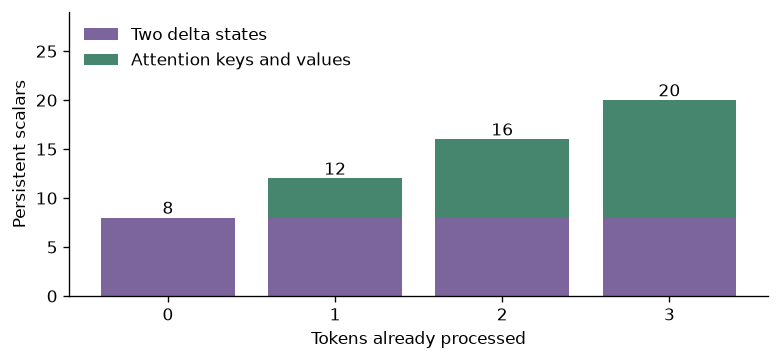

In [10]:
prefixes = np.arange(4)
fig, ax = plt.subplots(figsize=(6.6, 3.1))
ax.bar(prefixes, 8, label="Two delta states", color="#7c649c")
ax.bar(prefixes, 4 * prefixes, bottom=8,
       label="Attention keys and values", color="#46856e")
for n in prefixes:
    ax.text(n, 8 + 4 * n + 0.4, str(8 + 4 * n), ha="center")
ax.set(xlabel="Tokens already processed", ylabel="Persistent scalars",
       xticks=prefixes, ylim=(0, 29))
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

## 7. Change the middle mixer

Feed the same sequence $(1,2)$, $(0,1)$, $(-1,2)$ through
two three-layer stacks. The hybrid has delta, attention,
and delta mixers. The other has three delta mixers.
Each run starts with its own fresh stores and passes the
returned stores to the next token. Each mixer's output
becomes the next mixer's input for the same token.

For every token, `trace[0]` is the original representation.
Entries `trace[1]`, `trace[2]`, and `trace[3]` are the outputs
of the three successive mixers. Compare the first- and
third-layer outputs for the final token. Also inspect the
middle output and the last layer's state just before that
token to see where the difference comes from.

In [11]:
from examples.ch15_hybrids.model import initial_stores, stack_step

schedule_tokens = np.array(
    [[1, 2], [0, 1], [-1, 2]], dtype=np.float64
)
hybrid_schedule = ("delta", "attention", "delta")
delta_schedule = ("delta", "delta", "delta")
schedule_atol = 1e-12

def trace_schedule(schedule):
    stores = initial_stores(schedule)
    traces = []
    last_layer_states = []
    for token in schedule_tokens:
        trace, stores = stack_step(token, schedule, stores)
        traces.append(np.stack(trace))
        last_layer_states.append(stores[-1].copy())
    return np.stack(traces), np.stack(last_layer_states)

hybrid_trace, hybrid_last_states = trace_schedule(hybrid_schedule)
delta_trace, delta_last_states = trace_schedule(delta_schedule)

print("Final token, entries 0 through 3 in each trace")
with np.printoptions(precision=9, suppress=True):
    for i in range(4):
        print(f"{i}  hybrid {hybrid_trace[-1, i]}  "
              f"all-delta {delta_trace[-1, i]}")

Final token, entries 0 through 3 in each trace
0  hybrid [-1.  2.]  all-delta [-1.  2.]
1  hybrid [ 1.223955098 -0.471875   ]  all-delta [ 1.223955098 -0.471875   ]
2  hybrid [-0.035559528  1.059354575]  all-delta [-0.190662069  0.78165406 ]
3  hybrid [0.748677465 0.071532371]  all-delta [ 0.511765365 -0.05517097 ]


The first mixer has the same update rule, initial state,
and input history in both runs. In each case the query
and key are the incoming vector normalized to unit length.
The value swaps its two coordinates. The gates are
$\alpha=3/4$ and $\beta=1/2$. The first layer therefore
follows the same sequence of states and gives the same
representation for every token.

We can compute entry 1 of the final trace by hand.
Let $a=1/\sqrt{5}$ and write $S_1$ and $S_2$ for the first
layer's states after the first and second tokens. The first
key is $(a,2a)^\top$ and the value is $(2,1)^\top$.
From zero, the update is half their outer product.
The second token uses key $(0,1)^\top$, so after decay
only column 2 receives a correction.

$$
S_1=a\begin{bmatrix}1&2\\1/2&1\end{bmatrix},
\qquad
S_2=\begin{bmatrix}
3a/4&1/2+3a/4\\
3a/8&3a/8
\end{bmatrix}.
$$

For the third token, the query and key are both
$k=(-a,2a)^\top$, and the value is $v=(2,-1)^\top$.
The decayed prediction $p=(3/4)S_2 k$ is
$(3a/4+9/80,\;9/160)^\top$.
Reading along the same unit key after the update
gives $p+\tfrac12(v-p)=\tfrac12(p+v)$. The first
layer's final output is therefore
$(169/160+3a/8,\;-151/320)^\top$, approximately
$(1.223955098,\;-0.471875)$.

In [12]:
first_expected = np.array([
    169 / 160 + 3 / (8 * np.sqrt(5)),
    -151 / 320,
])
np.testing.assert_array_equal(hybrid_trace[:, 1], delta_trace[:, 1])
np.testing.assert_allclose(
    hybrid_trace[-1, 1], first_expected,
    rtol=0, atol=schedule_atol,
)

print("Layer 3 state before the final token")
for name, trace, states in (
    ("hybrid", hybrid_trace, hybrid_last_states),
    ("all-delta", delta_trace, delta_last_states),
):
    incoming = trace[-1, 2]
    key = incoming / np.linalg.norm(incoming)
    prediction = (0.75 * states[-2]) @ key
    recovered = 0.5 * (prediction + incoming[::-1])
    np.testing.assert_allclose(
        trace[-1, 3], recovered, rtol=0, atol=schedule_atol,
    )
    with np.printoptions(precision=9, suppress=True):
        print(name)
        print(states[-2])
final_difference = hybrid_trace[-1, 3] - delta_trace[-1, 3]
print("Final layer difference, hybrid minus all-delta")
with np.printoptions(precision=9, suppress=True):
    print(final_difference)

Layer 3 state before the final token
hybrid
[[0.264078288 0.593193751]
 [0.111645674 0.24204746 ]]
all-delta
[[0.141749596 0.366533414]
 [0.053401097 0.123259043]]
Final layer difference, hybrid minus all-delta
[0.2369121   0.126703341]


At entry 2, the hybrid's attention mixer reads from the
three stored keys and values. The all-delta middle mixer
instead reads its updated matrix state. The final token
reaches layer 3 as about $(-0.03556,1.05935)$ in the
hybrid and $(-0.19066,0.78165)$ in the all-delta stack.
Their preceding tokens also produced different middle
outputs, so layer 3 enters the final step with a different
matrix in each run.

The two last mixers follow the same rule. Each decays its
own preceding state, forms a new prediction along the
normalized incoming direction, and corrects toward the
swapped incoming value. This calculation reconstructs
that read from the saved preceding state and the current
middle output. The final outputs are about
$(0.74868,0.07153)$ and $(0.51177,-0.05517)$,
respectively. The last mixer type is the same, but both
the information entering it now and the information it
carried from earlier tokens have changed. The NumPy
comparisons use float64 with absolute tolerance $10^{-12}$
and zero relative tolerance, except for the exact check
between the identical first-layer traces.

## 8. Check the cache against a full pass (optional)

Use the one-layer schedule `("attention",)` and the three
input rows $(1,0)$, $(0,1)$, and $(1,1)$. In the teaching
attention layer, the query and key are the input itself
and the value swaps its two features. This gives
$Q=K$ equal to the input matrix and value rows
$(0,1)$, $(1,0)$, and $(1,1)$. In a full pass we compute
all the queries together. A Boolean lower-triangular
mask permits key $j$ for query $i$ exactly when $j\le i$.
The diagonal keeps each token's own key available.

The two-feature dot product is divided by $\sqrt{2}$.
For a hand check, put $s=1/\sqrt{2}$ and $r=e^{-s}$.
Subtracting the largest allowed score from each row before
exponentiating gives the following mixtures.

| Query | Allowed key positions | Allowed scores | Output |
| --: | :-- | :-- | :-- |
| 1 | 1 | $(s)$ | $(0,1)$ |
| 2 | 1, 2 | $(0,s)$ | $(1,r)/(1+r)$ |
| 3 | 1, 2, 3 | $(s,s,2s)$ | $(1+r,1+r)/(1+2r)$ |

For example, query 3 has normalized weights
$(r,r,1)/(1+2r)$. Both output coordinates receive a
contribution $1$ from the last value and a contribution
$r$ from one of the other values before division.

In [13]:
from examples.ch04_attention.attention import (
    scaled_dot_product_attention,
)

cache_tokens = np.array([[1, 0], [0, 1], [1, 1]], dtype=np.float64)
full_queries = cache_tokens.copy()
full_keys = cache_tokens.copy()
full_values = cache_tokens[:, ::-1].copy()
allowed = np.tri(len(cache_tokens), dtype=bool)
full_output, full_weights = scaled_dot_product_attention(
    full_queries, full_keys, full_values, allowed_mask=allowed,
)

r = np.exp(-1 / np.sqrt(2))
hand_output = np.array([
    [0.0, 1.0],
    [1 / (1 + r), r / (1 + r)],
    [(1 + r) / (1 + 2 * r)] * 2,
])
np.testing.assert_allclose(
    full_output, hand_output, rtol=0, atol=1e-12,
)
assert np.all(full_weights[~allowed] == 0)
print("Allowed mask, with 1 for an allowed read")
print(allowed.astype(int))
print("Full causal attention weights")
with np.printoptions(precision=9, suppress=True):
    print(full_weights)

Allowed mask, with 1 for an allowed read
[[1 0 0]
 [1 1 0]
 [1 1 1]]
Full causal attention weights
[[1.          0.          0.         ]
 [0.330238451 0.669761549 0.         ]
 [0.248255078 0.248255078 0.503489843]]


Now feed the tokens one at a time. The cache starts
empty, and each call appends the incoming key and value
before computing attention. The first call sees only
position 1. The second sees positions 1 and 2, and the
third sees all three. Thus each streaming query sees
exactly the entries its row of the full mask allows.
Check the contents of both cached arrays after every
call, and compare the last entry of each trace with
the corresponding full-pass output.

In [14]:
attention_only = ("attention",)
attention_stores = initial_stores(attention_only)
stream_outputs = []
print("Position  Key shape  Value shape")

for position, token in enumerate(cache_tokens, start=1):
    token_trace, attention_stores = stack_step(
        token, attention_only, attention_stores,
    )
    stream_outputs.append(token_trace[-1])
    keys, values = attention_stores[0]
    np.testing.assert_array_equal(keys, full_keys[:position])
    np.testing.assert_array_equal(values, full_values[:position])
    print(f"{position:>8}  {str(keys.shape):>9}  {values.shape}")

stream_output = np.stack(stream_outputs)
np.testing.assert_allclose(
    stream_output, full_output, rtol=0, atol=1e-12,
)
print("Full pass and streaming outputs, respectively")
with np.printoptions(precision=9, suppress=True):
    print(full_output)
    print(stream_output)
print("Maximum absolute difference",
      f"{np.max(np.abs(stream_output - full_output)):.3e}")

Position  Key shape  Value shape
       1     (1, 2)  (1, 2)
       2     (2, 2)  (2, 2)
       3     (3, 2)  (3, 2)
Full pass and streaming outputs, respectively
[[0.          1.         ]
 [0.669761549 0.330238451]
 [0.751744922 0.751744922]]
[[0.          1.         ]
 [0.669761549 0.330238451]
 [0.751744922 0.751744922]]
Maximum absolute difference 0.000e+00


The two methods give the same three output rows within
the float64 absolute tolerance $10^{-12}$ with zero
relative tolerance. The stored keys and values match
the full-pass projections exactly at every prefix.
Equality follows because each query uses the same
projection, scaling, and ordered set of visible keys
and values. In the streaming pass that set is defined
by the prefix already in the cache. In the full pass it
is defined by the Boolean mask.

For the causality check, replace only input three by $(3,-2)$. The first two rows of queries, keys and values are unchanged. Their masks exclude position three, so their outputs must remain unchanged. In the streaming calculation the third input has not even arrived when those outputs are formed. The third output can change because it reads its own new key and value as well as the preceding entries.

In [15]:
changed_tokens = cache_tokens.copy()
changed_tokens[2] = [3., -2.]
changed_full, _ = scaled_dot_product_attention(
    changed_tokens, changed_tokens, changed_tokens[:, ::-1],
    allowed_mask=allowed,
)
changed_stores = initial_stores(attention_only)
changed_stream = []
for token in changed_tokens:
    trace, changed_stores = stack_step(token, attention_only, changed_stores)
    changed_stream.append(trace[-1])
changed_stream = np.stack(changed_stream)
np.testing.assert_allclose(changed_stream, changed_full, atol=1e-12, rtol=0)
np.testing.assert_array_equal(changed_full[:2], full_output[:2])
np.testing.assert_array_equal(changed_stream[:2], stream_output[:2])
assert not np.allclose(changed_full[2], full_output[2])
print("Changes in output rows (changed minus original):")
print(changed_full - full_output)

Changes in output rows (changed minus original):
[[ 0.        0.      ]
 [ 0.        0.      ]
 [-2.749974  2.246484]]


## 9. Write to overlapping directions (optional)

There is one value coordinate, so $S$ is a row of length two. With no decay and a complete correction, $S_{\rm new}=S+(v-Sk)k^\top$. The first unit key $k_1=(1,0)^\top$ and value 2 give $S_1=(2,0)$ from a zero state.

For the overlapping key $k_2=(1/\sqrt2,1/\sqrt2)^\top$, the prediction is $\sqrt2$ and the error is $5-\sqrt2$. Hence

$$
S_2=(2,0)+(5-\sqrt2)(1/\sqrt2,1/\sqrt2)
=\left(1+\frac5{\sqrt2},\frac5{\sqrt2}-1\right).
$$

The second key reads exactly 5. The first key now reads $1+5/\sqrt2\approx4.535534$, rather than 2. The read-change formula predicts this: the second write changes the first read by $(5-\sqrt2)(k_2^\top k_1)=(5-\sqrt2)/\sqrt2$.

For the orthogonal second key $(0,1)^\top$, restart from zero and make the same first write. The second prediction is zero; the second write adds $(0,5)$ and gives $S_2=(2,5)$. Its two reads are 2 and 5. The inner product with the old key is zero, so that old read receives no correction.

| Second key | First read before | First read after | Second read after |
| :-- | --: | --: | --: |
| Overlapping | 2 | $1+5/\sqrt2\approx4.535534$ | 5 |
| Orthogonal | 2 | 2 | 5 |

Finally restore value 2 at $k_1$ in the overlapping run. This resets only the first coordinate, giving $S_3=(2,5/\sqrt2-1)$. The second key now reads $(2+5/\sqrt2-1)/\sqrt2=5/2+1/\sqrt2\approx3.207107$. Correcting the old association disturbed the newer one. Each individual unit-key write is exact at its own key; that does not make several overlapping associations independently editable.

In [16]:
first_key = np.array([1., 0.])
overlap_key = np.ones(2) / np.sqrt(2)
orthogonal_key = np.array([0., 1.])
overlap_states = []
for label, second_key in (("overlap", overlap_key),
                          ("orthogonal", orthogonal_key)):
    state = np.zeros((1, 2))
    _, state = delta_step(state, first_key, first_key, [2.], 1., 1.)
    first_state = state.copy()
    _, state = delta_step(state, second_key, second_key, [5.], 1., 1.)
    np.testing.assert_allclose(state @ second_key, [5.], atol=1e-12, rtol=0)
    print(label, "state", state, "first-key read", state @ first_key)
    if label == "overlap":
        np.testing.assert_allclose(state @ first_key, [1 + 5/np.sqrt(2)],
                                   atol=1e-12, rtol=0)
        second_state = state.copy()
        _, restored = delta_step(state, first_key, first_key, [2.], 1., 1.)
        np.testing.assert_allclose(restored @ overlap_key, [2.5 + 1/np.sqrt(2)],
                                   atol=1e-12, rtol=0)
        overlap_states = [first_state, second_state, restored]
    else:
        np.testing.assert_array_equal(state, [[2., 5.]])
print("After restoring the first key, second read:", restored @ overlap_key)

overlap state [[4.535534 2.535534]] first-key read [4.535534]
orthogonal state [[2. 5.]] first-key read [2.]
After restoring the first key, second read: [3.207107]


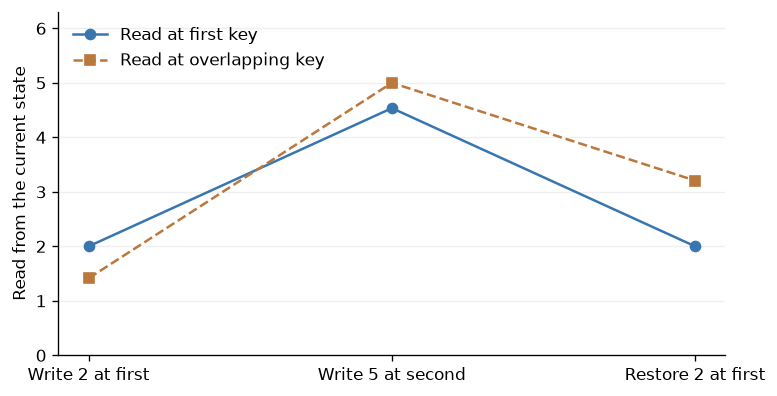

In [17]:
read_history = np.array([[float((s @ k).item())
                          for k in (first_key, overlap_key)]
                         for s in overlap_states])
fig, ax = plt.subplots(figsize=(6.6, 3.4))
ax.plot(range(3), read_history[:, 0], "o-", color="#3976af", label="Read at first key")
ax.plot(range(3), read_history[:, 1], "s--", color="#bb783d", label="Read at overlapping key")
ax.set(xticks=range(3), xticklabels=["Write 2 at first", "Write 5 at second", "Restore 2 at first"],
       ylabel="Read from the current state", ylim=(0, 6.3))
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", alpha=.2)
fig.tight_layout()
plt.show()

## 10. Plan a controlled comparison (optional)

Begin with a table mapping indices 0--3 to Ash, Birch, Cedar and Elm. Let the initial active index be 2. The moves advance, advance and retreat produce indices $3,0,3$. The same history supports three different questions:

| Question | Answer | Information needed |
| :-- | :-- | :-- |
| Address at index 1? | Birch | A specified entry of the early table |
| Current active index? | 3 | Initial index and subsequent moves |
| Address at current index? | Elm | Updated index, then the corresponding entry |

The first is recall, the second is tracking, and the third composes them. A reference generator should calculate the answers exactly before any model is evaluated.

In [18]:
addresses = ("Ash", "Birch", "Cedar", "Elm")
initial_index = 2
moves = (1, 1, -1)
trajectory = []
active = initial_index
for move in moves:
    active = (active + move) % len(addresses)
    trajectory.append(active)
assert trajectory == [3, 0, 3]
print("Trajectory:", trajectory)
print("Specified address:", addresses[1])
print("Current index:", active)
print("Current address:", addresses[active])

Trajectory: [3, 0, 3]
Specified address: Birch
Current index: 3
Current address: Elm


For a reproducible protocol, draw distinct address labels of equal token length and randomly assign them to indices on each sequence. Sample the initial index uniformly, state it explicitly, and draw moves independently of the table. Choose the specified-index query independently of the final index. Changing the mapping prevents a model from answering through a fixed learned index-to-address rule. Include paired histories with identical last messages but different earlier moves or initial indices, and others with identical trajectories but different table entries.

Train on tables with 4--8 entries and 8--32 moves. Test both within that range and beyond it, for example with 16 or 32 entries and 64 or 128 moves. Vary table size and move count separately before combining them, and record total token length as well. Increasing only the number of moves over a fixed eight-entry table does not increase the amount of arbitrary address information that must be retained. A sufficiently large fixed state could store that whole table.

Split complete table mappings and trajectory families into training, validation and test sets before combining them into questions. Reject a held-out mapping or an initial-index-plus-move sequence if it occurs in training; keep all three questions and any paired variants of one history in the same split. Use validation data for configuration and checkpoint selection. The candidate generator needs these split checks before use in a training experiment.

In [19]:
rng = np.random.default_rng(15)
print("entries  moves  initial  final  specified-index  answer labels")
for entries, count in ((4, 8), (8, 16), (16, 64), (32, 128)):
    # Integer IDs stand in for equally tokenized address labels.
    mapping = rng.permutation(entries)
    start = int(rng.integers(entries))
    updates = rng.choice([-1, 1], size=count)
    specified = int(rng.integers(entries))
    current = start
    for move in updates:
        current = (current + int(move)) % entries
    assert current == (start + int(updates.sum())) % entries
    answers = (int(mapping[specified]), current, int(mapping[current]))
    print(f"{entries:>7} {count:>6} {start:>8} {current:>6} "
          f"{specified:>16}  {answers}")

entries  moves  initial  final  specified-index  answer labels
      4      8        3      3                3  (1, 3, 1)
      8     16        6      6                5  (2, 6, 3)
     16     64        7      3               13  (7, 3, 0)
     32    128        4     30               18  (31, 30, 6)


Match causal depth, residual width, feed-forward sublayers, embeddings and output head across the three model families. Choose and report a fixed mixer schedule for the hybrid. Match tokenizer, training examples, training-token exposure, optimizer, learning-rate schedule and checkpoint selection rule; use several paired seeds. Mixer parameters and compute may still differ, so report them rather than claiming that equal width also equalizes total parameters or FLOPs. A second study can match a compute budget if that is the question of interest.

Measure exact match separately for recall, tracking and the combined question at every table size and move count. Use the same answer format and decoding rule for every model. Also report the fraction of histories on which all three answers are correct, and a diagnostic combined question that supplies the true final index. Correct tracking with an incorrect current address points toward trouble retrieving or using the indexed entry. Do not infer an architectural limitation from one failed training run.

Measure persistent history bytes per sequence just after the reports and before the question, using a common storage precision where feasible. Sum live K/V payloads and recurrent state plus convolution buffers across layers. Report reserved cache capacity separately. Parameters, saved output traces, temporary workspaces and allocator overhead are different quantities. At batch size one, a recurrent head with shape $[d_v,d_k]$ holds $s d_vd_k$ bytes, and a full-attention layer holds $s n H_{\rm KV}(d_k+d_v)$ bytes when all components use $s$ bytes per scalar. The teaching stacks below use float64 and no auxiliary buffers, so their bytes are eight times their scalar counts.

In [20]:
schedules = {"all-delta": ("delta",) * 3,
             "hybrid": ("delta", "attention", "delta"),
             "all-attention": ("attention",) * 3}
for prefix in (8, 32, 128):
    measured = {}
    for name, schedule in schedules.items():
        stores = initial_stores(schedule)
        for _ in range(prefix):
            _, stores = stack_step([1., 0.], schedule, stores)
        payload = sum(s.nbytes if isinstance(s, np.ndarray)
                      else sum(a.nbytes for a in s) for s in stores)
        measured[name] = payload
    expected = {"all-delta": 96, "hybrid": 8 * (4*prefix + 8),
                "all-attention": 96*prefix}
    assert measured == expected
    print(f"n={prefix}: {measured} bytes (toy stores only)")

n=8: {'all-delta': 96, 'hybrid': 320, 'all-attention': 768} bytes (toy stores only)
n=32: {'all-delta': 96, 'hybrid': 1088, 'all-attention': 3072} bytes (toy stores only)
n=128: {'all-delta': 96, 'hybrid': 4160, 'all-attention': 12288} bytes (toy stores only)


The circular task has a shortcut: the final index is the initial index plus the sum of the moves, modulo table size. The moves commute, so their order is irrelevant. It is a useful first pipeline check, but it does not reproduce the harder state-tracking problems used to study expressivity.

For an order-sensitive extension, let each update swap two index labels. A pointer at either label moves to the other; a pointer elsewhere stays put. Starting at index 1, swaps $(1,2)$ then $(2,3)$ produce $1\to2\to3$. Reversing those swaps gives $1\to1\to2$. The tables can stay fixed while the pointer changes. These updates remove the simple sum-of-moves shortcut, but performance still has to be measured in trained models; this generator and its oracle are not an empirical advantage for any architecture.

In [21]:
def apply_swaps(start, swaps):
    current = start
    path = [current]
    for left, right in swaps:
        if current == left:
            current = right
        elif current == right:
            current = left
        path.append(current)
    return path

forward_path = apply_swaps(1, [(1, 2), (2, 3)])
reverse_path = apply_swaps(1, [(2, 3), (1, 2)])
assert forward_path == [1, 2, 3]
assert reverse_path == [1, 1, 2]
print("Forward swap order:", forward_path)
print("Reverse swap order:", reverse_path)

Forward swap order: [1, 2, 3]
Reverse swap order: [1, 1, 2]
